In [ ]:
# Cell 1: Import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Locate the repository root
current = Path.cwd().resolve()

if (current / "data").is_dir():
    PROJECT_ROOT = current
elif (current.parent / "data").is_dir():
    PROJECT_ROOT = current.parent
else:
    raise FileNotFoundError("Could not locate the project's data folder.")

# Define data directories
RAW_DATA = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA = PROJECT_ROOT / "data" / "processed"

# Create processed folder if it does not exist
PROCESSED_DATA.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Raw data:", RAW_DATA)
print("Processed data:", PROCESSED_DATA)


Project root: C:\Users\harja\OneDrive - Danmarks Tekniske Universitet\DTU\Masters\BA\Project\DTU-Business-Analytics-2026
Raw data: C:\Users\harja\OneDrive - Danmarks Tekniske Universitet\DTU\Masters\BA\Project\DTU-Business-Analytics-2026\data\raw
Processed data: C:\Users\harja\OneDrive - Danmarks Tekniske Universitet\DTU\Masters\BA\Project\DTU-Business-Analytics-2026\data\processed


In [ ]:
# Cell 2: Load the original dataset directly from ZIP
import zipfile
zip_path = RAW_DATA / "Raw data.zip"
with zipfile.ZipFile(zip_path, "r") as z:
    csv_files = [
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    ]

    print("CSV files found:", csv_files)

    if len(csv_files) != 1:
        raise ValueError("Expected exactly one CSV file in the ZIP.")

    with z.open(csv_files[0]) as file:
        df = pd.read_csv(file)

original_columns = df.columns.tolist()
original_row_count = len(df)
df.head()


CSV files found: ['Raw data/EVChargingStationUsage.csv']


C:\Users\harja\AppData\Local\Temp\ipykernel_34056\2767323118.py:16: DtypeWarning: Columns (0: User ID, 1: County, 2: Model Number) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284.0,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169.0,NaN,NaN,NaN
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 8:16,PDT,7/30/2011 12:34,PDT,7/30/2011 12:34,4:17:32,4:17:28,...,-122.160309,USD,0.0,Plug Out at Vehicle,5,94301.0,4169.0,NaN,NaN,NaN
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 14:51,PDT,7/30/2011 16:55,PDT,7/30/2011 16:55,2:03:24,2:02:58,...,-122.160309,USD,0.0,Customer,6,94302.0,2545.0,NaN,NaN,NaN
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 18:51,PDT,7/30/2011 20:03,PDT,7/30/2011 20:03,1:11:24,0:43:54,...,-122.160309,USD,0.0,Plug Out at Vehicle,7,94043.0,3765.0,NaN,NaN,NaN


In [ ]:
# Cell 3: Check dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 259415
Number of columns: 33


In [ ]:
# Cell 4: Inspect the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 259415 entries, 0 to 259414
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Station Name                     259415 non-null  str    
 1   MAC Address                      259415 non-null  str    
 2   Org Name                         259415 non-null  str    
 3   Start Date                       259415 non-null  str    
 4   Start Time Zone                  259415 non-null  str    
 5   End Date                         259415 non-null  str    
 6   End Time Zone                    259415 non-null  str    
 7   Transaction Date (Pacific Time)  259206 non-null  str    
 8   Total Duration (hh:mm:ss)        259415 non-null  str    
 9   Charging Time (hh:mm:ss)         259415 non-null  str    
 10  Energy (kWh)                     259415 non-null  float64
 11  GHG Savings (kg)                 259415 non-null  float64
 12  Gasoline Savi

In [ ]:
# Cell 5: Summarize numerical variables
df.describe()

,Energy (kWh),GHG Savings (kg),Gasoline Savings (gallons),Port Number,EVSE ID,Postal Code,Latitude,Longitude,Fee,Plug In Event Id,Driver Postal Code,System S/N
count,259415.000000,259415.000000,259415.000000,259415.000000,1.804670e+05,259415.000000,259415.000000,259415.000000,259415.000000,2.594150e+05,251013.000000,1.804670e+05
mean,8.544277,3.588596,1.072306,1.591627,1.462973e+05,94302.315768,37.439565,-122.151264,1.097481,1.188685e+08,94170.308255,1.443790e+11
std,7.185462,3.017894,0.901776,0.491534,2.429677e+05,1.941657,0.009621,0.015382,1.934408,4.057750e+08,4249.837126,2.483280e+10
min,0.010000,0.004000,0.001000,1.000000,3.792000e+03,94301.000000,37.422104,-122.163239,0.000000,1.000000e+00,1013.000000,1.023100e+11
25%,3.784000,1.589000,0.475000,1.000000,4.358300e+04,94301.000000,37.428318,-122.162170,0.000000,1.573000e+03,94087.000000,1.231100e+11
50%,6.868634,2.885000,0.862000,2.000000,1.074270e+05,94301.000000,37.444489,-122.158272,0.000000,3.573000e+03,94304.000000,1.427410e+11
75%,11.458340,4.813000,1.438000,2.000000,1.745590e+05,94303.000000,37.446613,-122.145699,1.640000,6.340000e+03,94804.000000,1.705410e+11
max,97.360000,40.891000,12.219000,2.000000,5.535441e+06,94306.000000,37.449375,-122.112480,84.560000,1.609436e+09,99354.000000,2.002410e+11


In [ ]:
# Cell 6: Check missing values
missing_values = df.isnull().sum()

# Calculate percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Combine into a table
missing_summary = pd.DataFrame({
    "Missing Count": missing_values,
    "Missing Percentage": missing_percentage
})

# Display only columns containing missing values
missing_summary[missing_summary["Missing Count"] > 0].sort_values(
    by="Missing Percentage",
    ascending=False
).round(2)

,Missing Count,Missing Percentage
County,84665,32.64
EVSE ID,78948,30.43
System S/N,78948,30.43
Model Number,78948,30.43
Driver Postal Code,8402,3.24
User ID,7677,2.96
Currency,1788,0.69
Ended By,248,0.10
Transaction Date (Pacific Time),209,0.08
Port Type,9,0.00


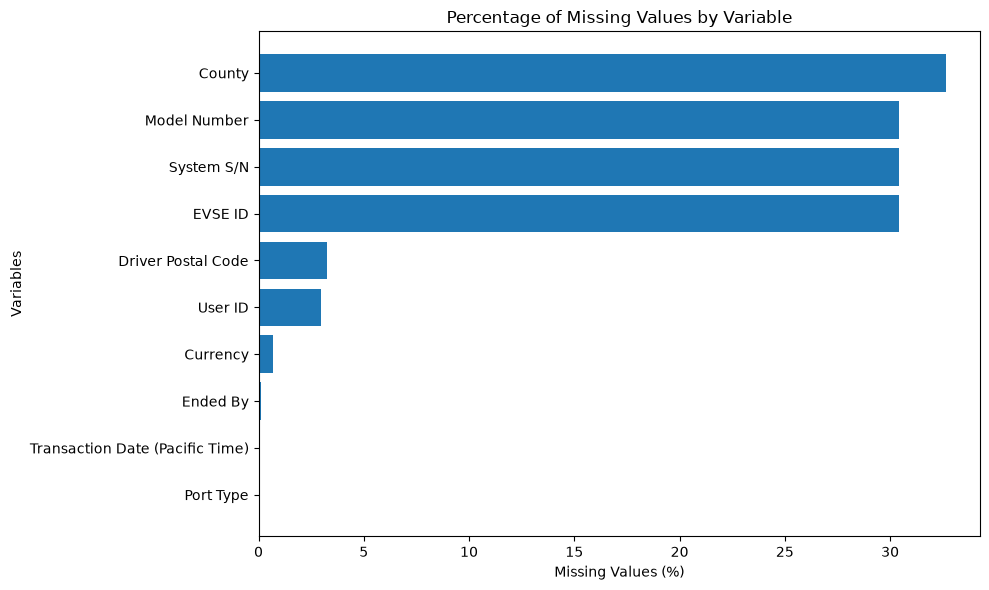

In [ ]:
# Cell 7: Plot missing values
missing_plot = missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values("Missing Percentage")

plt.figure(figsize=(10, 6))

plt.barh(
    missing_plot.index,
    missing_plot["Missing Percentage"]
)

plt.xlabel("Missing Values (%)")
plt.ylabel("Variables")
plt.title("Percentage of Missing Values by Variable")

plt.tight_layout()
plt.show()


In [ ]:
# Cell 8: Count exact duplicates
duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)
print("Percentage of duplicate rows:",
      round(duplicates / len(df) * 100, 2), "%")


Number of duplicate rows: 4
Percentage of duplicate rows: 0.0 %


In [ ]:
# Cell 9: Check repeated event IDs
duplicate_events = df["Plug In Event Id"].duplicated().sum()

print("Number of repeated charging event IDs:", duplicate_events)

Number of repeated charging event IDs: 222577


In [ ]:
# Cell 10: Inspect repeated event IDs
event_counts = df["Plug In Event Id"].value_counts()

print("Number of unique event IDs:", df["Plug In Event Id"].nunique())

print("\nMost frequently repeated event IDs:")
print(event_counts.head(10))

Number of unique event IDs: 36838

Most frequently repeated event IDs:
Plug In Event Id
657    257
100     52
152     51
345     51
406     51
91      50
112     50
113     50
125     50
130     50
Name: count, dtype: int64


In [ ]:
# Cell 11: Compare sessions sharing an event ID
example_id = event_counts.index[0]

# Show some charging sessions sharing this ID
columns_to_view = [
    "Plug In Event Id",
    "Station Name",
    "Port Number",
    "Start Date",
    "End Date",
    "Energy (kWh)",
    "User ID"
]

df.loc[
    df["Plug In Event Id"] == example_id,
    columns_to_view
].head(10)

,Plug In Event Id,Station Name,Port Number,Start Date,End Date,Energy (kWh),User ID
1869,657,PALO ALTO CA / HAMILTON #1,2,2/23/2012 23:14,2/24/2012 4:19,9.282277,0.0
1899,657,PALO ALTO CA / HAMILTON #2,2,2/25/2012 23:16,2/26/2012 10:20,11.995232,2670.0
3546,657,PALO ALTO CA / BRYANT #2,2,5/30/2012 12:10,5/30/2012 14:44,9.357014,5717.0
3634,657,PALO ALTO CA / HIGH #4,2,6/3/2012 10:03,6/3/2012 10:55,3.191070,0.0
3869,657,PALO ALTO CA / BRYANT #1,2,6/15/2012 8:37,6/15/2012 11:44,9.503218,48863.0
17909,657,PALO ALTO CA / BRYANT #2,2,12/29/2013 12:19,12/29/2013 13:21,3.743120,6666.0
34483,657,PALO ALTO CA / MPL #6,1,4/5/2015 10:47,4/5/2015 15:06,18.803009,273507
35798,657,PALO ALTO CA / MPL #4,1,4/29/2015 11:23,4/29/2015 12:14,5.180361,163019
35822,657,PALO ALTO CA / MPL #4,1,4/29/2015 16:49,4/29/2015 17:19,1.810477,200507
35825,657,PALO ALTO CA / MPL #4,1,4/29/2015 17:22,4/29/2015 18:47,4.467847,184285


In [ ]:
# Cell 12: Inspect exact duplicate rows
duplicate_rows = df[df.duplicated(keep=False)]

print("Total rows involved:", len(duplicate_rows))

display(duplicate_rows)

Total rows involved: 8


,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
32433,PALO ALTO CA / MPL #6,000D6F00015B7509,City of Palo Alto,2/25/2015 15:24,PST,2/25/2015 15:46,PST,2/25/2015 15:46,0:22:23,0:22:10,...,-122.113457,USD,0.00,Plug Out at Vehicle,469,95134.0,318799.0,NaN,NaN,NaN
32434,PALO ALTO CA / MPL #6,000D6F00015B7509,City of Palo Alto,2/25/2015 15:24,PST,2/25/2015 15:46,PST,2/25/2015 15:46,0:22:23,0:22:10,...,-122.113457,USD,0.00,Plug Out at Vehicle,469,95134.0,318799.0,NaN,NaN,NaN
108235,PALO ALTO CA / HIGH #2,0024:B100:0002:5959,City of Palo Alto,2/27/2017 11:14,PST,2/27/2017 14:17,PST,2/27/2017 14:17,3:02:42,2:33:45,...,-122.163017,USD,0.00,Plug Out at Vehicle,1488222853,94301.0,738281,Santa Clara County,1.640410e+11,CT4020-HD
108236,PALO ALTO CA / HIGH #2,0024:B100:0002:5959,City of Palo Alto,2/27/2017 11:14,PST,2/27/2017 14:17,PST,2/27/2017 14:17,3:02:42,2:33:45,...,-122.163017,USD,0.00,Plug Out at Vehicle,1488222853,94301.0,738281,Santa Clara County,1.640410e+11,CT4020-HD
109966,PALO ALTO CA / BRYANT #2,000D:6F00:009D:CFC3,City of Palo Alto,3/10/2017 14:07,PST,3/10/2017 15:53,PST,3/10/2017 15:53,1:46:01,1:24:31,...,-122.162140,USD,0.00,Customer,9453,94065.0,548777,Santa Clara County,1.023100e+11,CT2100-HD-CCR
109967,PALO ALTO CA / BRYANT #2,000D:6F00:009D:CFC3,City of Palo Alto,3/10/2017 14:07,PST,3/10/2017 15:53,PST,3/10/2017 15:53,1:46:01,1:24:31,...,-122.162140,USD,0.00,Customer,9453,94065.0,548777,Santa Clara County,1.023100e+11,CT2100-HD-CCR
206764,PALO ALTO CA / BRYANT #5,0024:B100:0002:6D51,City of Palo Alto,4/29/2019 8:10,PDT,4/29/2019 9:09,PDT,4/29/2019 9:10,0:59:06,0:57:54,...,-122.162231,USD,1.33,Plug Out at Vehicle,3413,94027.0,4516921.0,Santa Clara County,1.707410e+11,CT4020-HD
206765,PALO ALTO CA / BRYANT #5,0024:B100:0002:6D51,City of Palo Alto,4/29/2019 8:10,PDT,4/29/2019 9:09,PDT,4/29/2019 9:10,0:59:06,0:57:54,...,-122.162231,USD,1.33,Plug Out at Vehicle,3413,94027.0,4516921.0,Santa Clara County,1.707410e+11,CT4020-HD


In [ ]:
# Cell 13: Inspect duplicate session details
columns_to_check = [
    "Plug In Event Id",
    "Station Name",
    "Port Number",
    "Start Date",
    "End Date",
    "Total Duration (hh:mm:ss)",
    "Charging Time (hh:mm:ss)",
    "Energy (kWh)",
    "User ID"
]

display(
    duplicate_rows[columns_to_check].sort_values(
        by=["Plug In Event Id", "Start Date"]
    )
)

,Plug In Event Id,Station Name,Port Number,Start Date,End Date,Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),Energy (kWh),User ID
32433,469,PALO ALTO CA / MPL #6,1,2/25/2015 15:24,2/25/2015 15:46,0:22:23,0:22:10,1.186864,318799.0
32434,469,PALO ALTO CA / MPL #6,1,2/25/2015 15:24,2/25/2015 15:46,0:22:23,0:22:10,1.186864,318799.0
206764,3413,PALO ALTO CA / BRYANT #5,2,4/29/2019 8:10,4/29/2019 9:09,0:59:06,0:57:54,5.780000,4516921.0
206765,3413,PALO ALTO CA / BRYANT #5,2,4/29/2019 8:10,4/29/2019 9:09,0:59:06,0:57:54,5.780000,4516921.0
109966,9453,PALO ALTO CA / BRYANT #2,2,3/10/2017 14:07,3/10/2017 15:53,1:46:01,1:24:31,4.385000,548777
109967,9453,PALO ALTO CA / BRYANT #2,2,3/10/2017 14:07,3/10/2017 15:53,1:46:01,1:24:31,4.385000,548777
108235,1488222853,PALO ALTO CA / HIGH #2,1,2/27/2017 11:14,2/27/2017 14:17,3:02:42,2:33:45,8.538000,738281
108236,1488222853,PALO ALTO CA / HIGH #2,1,2/27/2017 11:14,2/27/2017 14:17,3:02:42,2:33:45,8.538000,738281


In [ ]:
# Cell 14: Remove exact duplicate rows
df = df.drop_duplicates().copy()

print("Remaining rows:", len(df))
print("Remaining duplicates:", df.duplicated().sum())

Remaining rows: 259411
Remaining duplicates: 0


In [ ]:
# Cell 15: Check energy values and fees
print("Negative energy values:",
      (df["Energy (kWh)"] < 0).sum())

print("Zero energy values:",
      (df["Energy (kWh)"] == 0).sum())

print("Negative fees:",
      (df["Fee"] < 0).sum())

print("Zero fees:",
      (df["Fee"] == 0).sum())

Negative energy values: 0
Zero energy values: 0
Negative fees: 0
Zero fees: 133535


In [ ]:
# Cell 16: Convert connection and charging durations to hours
df["Total Duration Hours"] = (
    pd.to_timedelta(df["Total Duration (hh:mm:ss)"])
    .dt.total_seconds() / 3600
)

df["Charging Time Hours"] = (
    pd.to_timedelta(df["Charging Time (hh:mm:ss)"])
    .dt.total_seconds() / 3600
)

# Calculate additional connection time
df["Idle Time Hours"] = (
    df["Total Duration Hours"] - df["Charging Time Hours"]
)

# Display summary statistics
df[[
    "Total Duration Hours",
    "Charging Time Hours",
    "Idle Time Hours"
]].describe().round(2)

,Total Duration Hours,Charging Time Hours,Idle Time Hours
count,259411.00,259411.00,259411.00
mean,2.49,2.00,0.49
std,2.21,1.38,1.48
min,0.02,0.00,-11.56
25%,1.17,1.04,0.00
50%,2.09,1.82,0.01
75%,3.09,2.70,0.35
max,114.54,22.93,112.55


In [ ]:
# Cell 17: Check invalid durations
print("Negative total durations:",
      (df["Total Duration Hours"] < 0).sum())

print("Zero total durations:",
      (df["Total Duration Hours"] == 0).sum())

print("Negative charging times:",
      (df["Charging Time Hours"] < 0).sum())

print("Zero charging times:",
      (df["Charging Time Hours"] == 0).sum())

print("Charging time exceeds total duration:",
      (df["Idle Time Hours"] < 0).sum())


Negative total durations: 0
Zero total durations: 0
Negative charging times: 0
Zero charging times: 0
Charging time exceeds total duration: 45


In [ ]:
# Cell 18: Count and inspect extreme connection durations
for limit in [10, 11, 12, 24, 48, 72, 100]:
    count = (df["Total Duration Hours"] > limit).sum()

    print(f"Sessions exceeding {limit} hours: {count}")

# Examine all sessions exceeding 24 hours
extreme_sessions = df[
    df["Total Duration Hours"] > 24
].copy()

display(
    extreme_sessions[[
        "Station Name",
        "Start Date",
        "End Date",
        "Total Duration Hours",
        "Charging Time Hours",
        "Idle Time Hours",
        "Energy (kWh)"
    ]].sort_values("Total Duration Hours", ascending=False)
)


Sessions exceeding 10 hours: 5081
Sessions exceeding 11 hours: 3716
Sessions exceeding 12 hours: 2598
Sessions exceeding 24 hours: 22
Sessions exceeding 48 hours: 6
Sessions exceeding 72 hours: 5
Sessions exceeding 100 hours: 4


,Station Name,Start Date,End Date,Total Duration Hours,Charging Time Hours,Idle Time Hours,Energy (kWh)
222744,PALO ALTO CA / CAMBRIDGE #1,8/29/2019 12:35,9/3/2019 7:07,114.539167,2.065000,112.474167,6.711
222758,PALO ALTO CA / CAMBRIDGE #2,8/29/2019 13:34,9/3/2019 7:07,113.544444,0.997222,112.547222,3.740
222763,PALO ALTO CA / CAMBRIDGE #2,8/29/2019 14:03,9/3/2019 7:07,113.071111,0.594722,112.476389,1.860
222765,PALO ALTO CA / CAMBRIDGE #1,8/29/2019 14:19,9/3/2019 7:07,112.796389,0.327500,112.468889,1.976
249648,PALO ALTO CA / RINCONADA LIB 2,3/20/2020 18:46,3/24/2020 7:44,84.967222,8.774722,76.192500,49.020
251855,PALO ALTO CA / RINCONADA LIB 2,6/23/2020 16:01,6/25/2020 17:33,49.518889,10.357222,39.161667,61.505
249505,PALO ALTO CA / RINCONADA LIB 3,3/15/2020 16:47,3/17/2020 15:49,47.038056,8.252222,38.785833,43.113
168212,PALO ALTO CA / RINCONADA LIB 1,6/15/2018 16:22,6/17/2018 12:36,44.230556,3.271667,40.958889,18.203
159576,PALO ALTO CA / HIGH #2,4/6/2018 20:14,4/8/2018 16:15,44.016111,3.468333,40.547778,20.421
177004,PALO ALTO CA / CAMBRIDGE #4,8/28/2018 19:03,8/30/2018 11:01,39.972222,1.192778,38.779444,3.942


In [ ]:
# Cell 19: Flag sessions exceeding 24 hours
duration_threshold = 24

# Flag sessions exceeding the threshold
df["Exceeds 24 Hours"] = (
    df["Total Duration Hours"] > duration_threshold
)

print("Sessions exceeding 24 hours:",
      df["Exceeds 24 Hours"].sum())

print("Sessions within 24 hours:",
      (~df["Exceeds 24 Hours"]).sum())


Sessions exceeding 24 hours: 22
Sessions within 24 hours: 259389


In [ ]:
# Cell 20: Convert dates and compare connection durations
df["Start Date"] = pd.to_datetime(
    df["Start Date"], errors="coerce"
)

df["End Date"] = pd.to_datetime(
    df["End Date"], errors="coerce"
)

# Calculate duration based on timestamps
df["Calculated Duration Hours"] = (
    (df["End Date"] - df["Start Date"])
    .dt.total_seconds() / 3600
)

# Compare calculated and recorded durations
df["Duration Difference Hours"] = (
    df["Calculated Duration Hours"]
    - df["Total Duration Hours"]
)

print("Invalid start dates:", df["Start Date"].isna().sum())
print("Invalid end dates:", df["End Date"].isna().sum())

print("Negative calculated durations:",
      (df["Calculated Duration Hours"] < 0).sum())

print("Differences greater than 5 minutes:",
      (df["Duration Difference Hours"].abs() > 5/60).sum())

display(df["Duration Difference Hours"].describe())


Invalid start dates: 0
Invalid end dates: 40
Negative calculated durations: 31
Differences greater than 5 minutes: 433


count    259371.000000
mean          0.097366
std          10.386647
min         -10.542500
25%          -0.005000
50%           0.000000
75%           0.004722
max        1973.964167
Name: Duration Difference Hours, dtype: float64

In [ ]:
# Cell 21: Inspect invalid end date values
df_raw = pd.read_csv(r'C:\Users\harja\OneDrive - Danmarks Tekniske Universitet\DTU\Masters\BA\Project\EVChargingStationUsage.csv\EVChargingStationUsage.csv', low_memory=False)
invalid_end_indices = df.index[df["End Date"].isna()]
print("Invalid end dates:", len(invalid_end_indices))
display(df_raw.loc[invalid_end_indices, [
    "Start Date", "End Date", "Total Duration (hh:mm:ss)", "Station Name"
]].head(15))

Invalid end dates: 40


,Start Date,End Date,Total Duration (hh:mm:ss),Station Name
116186,4/20/2017 13:09,42845.81041,6:17:46,PALO ALTO CA / TED THOMPSON #1
116193,4/20/2017 14:05,42845.74654,3:49:40,PALO ALTO CA / HIGH #2
116196,4/20/2017 14:10,42845.79442,4:53:06,PALO ALTO CA / HIGH #3
116197,4/20/2017 14:15,42845.79878,4:54:39,PALO ALTO CA / CAMBRIDGE #1
116198,4/20/2017 14:16,42845.79485,4:47:49,PALO ALTO CA / HIGH #2
116204,4/20/2017 14:55,42845.6772,1:19:36,PALO ALTO CA / HIGH #3
116205,4/20/2017 15:01,42845.76139,3:14:48,PALO ALTO CA / HAMILTON #1
116206,4/20/2017 15:12,42845.76208,3:04:40,PALO ALTO CA / TED THOMPSON #1
116209,4/20/2017 15:18,42845.71704,1:54:06,PALO ALTO CA / MPL #5
116211,4/20/2017 15:24,42845.70417,1:29:15,PALO ALTO CA / BRYANT #3


In [ ]:
# Cell 22: Inspect negative timestamp durations
negative_durations = df[
    df["Calculated Duration Hours"] < 0
]

display(
    negative_durations[[
        "Station Name",
        "Start Date",
        "End Date",
        "Calculated Duration Hours",
        "Total Duration Hours"
    ]].head(15)
)


,Station Name,Start Date,End Date,Calculated Duration Hours,Total Duration Hours
16212,PALO ALTO CA / HAMILTON #1,2013-10-29 16:53:00,2013-10-29 13:59:00,-2.900000,1.087222
19198,PALO ALTO CA / HAMILTON #2,2014-02-10 19:14:00,2014-02-10 14:17:00,-4.950000,3.046389
19227,PALO ALTO CA / HAMILTON #2,2014-02-11 19:08:00,2014-02-11 11:47:00,-7.350000,0.649722
19228,PALO ALTO CA / HAMILTON #2,2014-02-11 19:56:00,2014-02-11 14:15:00,-5.683333,2.322500
19231,PALO ALTO CA / HIGH #4,2014-02-11 22:14:00,2014-02-11 16:21:00,-5.883333,2.107778
19349,PALO ALTO CA / HAMILTON #2,2014-02-15 15:43:00,2014-02-15 14:12:00,-1.516667,6.488889
19759,PALO ALTO CA / HAMILTON #2,2014-03-01 23:28:00,2014-03-01 16:00:00,-7.466667,0.531111
19854,PALO ALTO CA / HAMILTON #1,2014-03-05 18:18:00,2014-03-05 12:58:00,-5.333333,2.671944
19904,PALO ALTO CA / HAMILTON #1,2014-03-08 07:09:00,2014-03-07 23:28:00,-7.683333,0.325000
54026,PALO ALTO CA / WEBSTER #3,2016-01-14 21:10:00,2016-01-14 17:47:00,-3.383333,4.608889


In [ ]:
# Cell 23: Inspect largest timestamp discrepancies
display(
    df.loc[
        df["Duration Difference Hours"].abs().nlargest(10).index,
        [
            "Station Name",
            "Start Date",
            "End Date",
            "Total Duration Hours",
            "Calculated Duration Hours",
            "Duration Difference Hours"
        ]
    ]
)


,Station Name,Start Date,End Date,Total Duration Hours,Calculated Duration Hours,Duration Difference Hours
38666,PALO ALTO CA / MPL #6,2015-06-18 13:01:00,2015-09-08 20:24:00,1.419167,1975.383333,1973.964167
38664,PALO ALTO CA / MPL #5,2015-06-18 12:10:00,2015-09-08 20:21:00,2.300278,1976.183333,1973.883056
38606,PALO ALTO CA / MPL #4,2015-06-17 13:04:00,2015-08-27 09:57:00,0.503611,1700.883333,1700.379722
38609,PALO ALTO CA / MPL #4,2015-06-17 14:24:00,2015-08-27 09:57:00,1.430833,1699.550000,1698.119167
38644,PALO ALTO CA / MPL #4,2015-06-18 06:28:00,2015-08-27 09:57:00,1.422778,1683.483333,1682.060556
38673,PALO ALTO CA / MPL #4,2015-06-18 13:55:00,2015-08-27 09:57:00,0.086111,1676.033333,1675.947222
38674,PALO ALTO CA / MPL #4,2015-06-18 14:13:00,2015-08-27 09:57:00,0.255000,1675.733333,1675.478333
39195,PALO ALTO CA / MPL #4,2015-06-30 13:14:00,2015-08-27 09:57:00,0.337778,1388.716667,1388.378889
2389,PALO ALTO CA / HAMILTON #1,2012-03-27 14:40:00,2012-05-09 12:43:00,22.999722,1030.050000,1007.050278
16244,PALO ALTO CA / HAMILTON #2,2013-10-30 17:28:00,2013-12-06 09:45:00,22.999722,880.283333,857.283611


In [ ]:
# Cell 24: Compare inconsistent and extreme duration counts
invalid_duration = df["Charging Time Hours"] > df["Total Duration Hours"]
long_duration = df["Total Duration Hours"] > duration_threshold
print("Sessions with inconsistent durations:", invalid_duration.sum())
print(f"Sessions exceeding {duration_threshold} hours:", long_duration.sum())
print("Sessions with both conditions:", (long_duration & invalid_duration).sum())

Sessions with inconsistent durations: 45
Sessions exceeding 24 hours: 22
Sessions with both conditions: 0


In [ ]:

# Cell 25: Correct Excel-formatted end dates
# Identify invalid end dates
mask = df["End Date"].isna()

# Retrieve original Excel serial numbers
excel_values = pd.to_numeric(
    df_raw["End Date"].reindex(df.index[mask]),
    errors="coerce"
)

# Convert Excel serial numbers to datetime
converted_dates = pd.to_datetime(
    excel_values,
    unit="D",
    origin="1899-12-30",
    errors="coerce"
)

# Match datetime precision before assigning
df["End Date"] = df["End Date"].astype("datetime64[ns]")

# Update the End Date column
df.loc[mask, "End Date"] = converted_dates

# Check results
print("Corrected end dates:", converted_dates.notna().sum())
print("Remaining invalid end dates:", df["End Date"].isna().sum())



Corrected end dates: 40
Remaining invalid end dates: 0


In [ ]:
# Cell 26: Recalculate durations after correcting dates
df["Calculated Duration Hours"] = (
    (df["End Date"] - df["Start Date"])
    .dt.total_seconds() / 3600
)

df["Duration Difference Hours"] = (
    df["Calculated Duration Hours"]
    - df["Total Duration Hours"]
)

print("Invalid end dates:",
      df["End Date"].isna().sum())

print("Negative calculated durations:",
      (df["Calculated Duration Hours"] < 0).sum())

print("Differences greater than 5 minutes:",
      (df["Duration Difference Hours"].abs() > 5/60).sum())


Invalid end dates: 0
Negative calculated durations: 31
Differences greater than 5 minutes: 433


In [ ]:
# Cell 27: Summarize timestamp problems by station
problematic_sessions = df[
    df["Duration Difference Hours"].abs() > 5/60
].copy()

print("Problematic sessions:", len(problematic_sessions))

# Count problematic sessions by station
station_problems = (
    problematic_sessions["Station Name"]
    .value_counts()
)

display(station_problems.head(15))


Problematic sessions: 433


Station Name
PALO ALTO CA / BRYANT #2          84
PALO ALTO CA / HIGH #4            45
PALO ALTO CA / HAMILTON #1        43
PALO ALTO CA / HAMILTON #2        39
PALO ALTO CA / BRYANT #1          38
PALO ALTO CA / WEBSTER #1         26
PALO ALTO CA / MPL #4             24
PALO ALTO CA / MPL #6             16
PALO ALTO CA / WEBSTER #2         15
PALO ALTO CA / MPL #5             12
PALO ALTO CA / WEBSTER #3         12
PALO ALTO CA / BRYANT #3           9
PALO ALTO CA / RINCONADA LIB 2     8
PALO ALTO CA / MPL #2              7
PALO ALTO CA / HIGH #1             7
Name: count, dtype: int64

In [ ]:
# Cell 28: Summarize timestamp problems by date
date_problems = (
    problematic_sessions["Start Date"]
    .dt.date
    .value_counts()
)

display(date_problems.head(15))


Start Date
2017-03-13    26
2015-11-02    24
2017-12-13    15
2013-10-03    10
2016-11-05     9
2016-03-12     7
2016-08-15     6
2017-12-14     6
2013-04-18     5
2014-02-11     5
2015-06-18     5
2013-02-21     4
2013-04-19     4
2013-07-09     4
2014-06-26     4
Name: count, dtype: int64

In [ ]:
# Cell 29: Categorize timestamp difference sizes
difference_minutes = (
    problematic_sessions["Duration Difference Hours"].abs() * 60
)

print("Between 5 and 60 minutes:",
      ((difference_minutes > 5) & (difference_minutes <= 60)).sum())

print("Between 1 and 24 hours:",
      ((difference_minutes > 60) & (difference_minutes <= 1440)).sum())

print("More than 24 hours:",
      (difference_minutes > 1440).sum())


Between 5 and 60 minutes: 137
Between 1 and 24 hours: 210
More than 24 hours: 86


In [ ]:
# Cell 30: Flag timestamp and charging duration inconsistencies
df["Timestamp Error"] = (
    df["Duration Difference Hours"].abs() > 5/60
)

# Flag sessions where charging time exceeds total duration
df["Charging Duration Error"] = (
    df["Charging Time Hours"] > df["Total Duration Hours"]
)

# Count overlapping errors
both_errors = (
    df["Timestamp Error"] & df["Charging Duration Error"]
).sum()

timestamp_only = (
    df["Timestamp Error"] & ~df["Charging Duration Error"]
).sum()

charging_only = (
    ~df["Timestamp Error"] & df["Charging Duration Error"]
).sum()

print("Both types of errors:", both_errors)
print("Timestamp errors only:", timestamp_only)
print("Charging duration errors only:", charging_only)

print("Total sessions with at least one error:",
      (df["Timestamp Error"] | df["Charging Duration Error"]).sum())


Both types of errors: 39
Timestamp errors only: 394
Charging duration errors only: 6
Total sessions with at least one error: 439


In [ ]:
# Cell 31: Inspect cases of negative idle time
negative_idle = df[df["Idle Time Hours"] < 0].copy()

# Convert the difference to minutes
negative_idle["Excess Charging Minutes"] = (
    -negative_idle["Idle Time Hours"] * 60
)

# Summarize the size of the errors
print("Less than or equal to 1 minute:",
      (negative_idle["Excess Charging Minutes"] <= 1).sum())

print("More than 1 minute, up to 10 minutes:",
      ((negative_idle["Excess Charging Minutes"] > 1) &
       (negative_idle["Excess Charging Minutes"] <= 10)).sum())

print("More than 10 minutes:",
      (negative_idle["Excess Charging Minutes"] > 10).sum())

# Display the largest inconsistencies
display(
    negative_idle.nlargest(
        10, "Excess Charging Minutes"
    )[[
        "Station Name",
        "Start Date",
        "End Date",
        "Total Duration Hours",
        "Charging Time Hours",
        "Excess Charging Minutes"
    ]]
)


Less than or equal to 1 minute: 5
More than 1 minute, up to 10 minutes: 3
More than 10 minutes: 37


,Station Name,Start Date,End Date,Total Duration Hours,Charging Time Hours,Excess Charging Minutes
116499,PALO ALTO CA / BRYANT #3,2017-04-22 13:15:00,2017-04-23 14:28:00,1.210000,12.768333,693.500000
20946,PALO ALTO CA / HAMILTON #2,2014-04-12 07:46:00,2014-04-13 10:31:00,2.750000,13.112778,621.766667
117551,PALO ALTO CA / WEBSTER #2,2017-04-29 10:16:00,2017-04-30 12:02:00,1.777778,11.419167,578.483333
29148,PALO ALTO CA / MPL #2,2014-12-15 17:57:00,2014-12-16 20:01:00,2.059167,10.705278,518.766667
34752,PALO ALTO CA / BRYANT #2,2015-04-10 08:15:00,2015-04-14 08:33:00,0.305000,8.766944,507.716667
89485,PALO ALTO CA / HAMILTON #2,2016-10-15 15:36:00,2016-10-16 18:02:00,2.426389,9.542500,426.966667
109214,PALO ALTO CA / RINCONADA LIB 2,2017-03-05 17:14:00,2017-03-06 17:51:00,0.617500,7.300556,400.983333
120874,PALO ALTO CA / BRYANT #3,2017-05-19 15:49:00,2017-05-20 16:55:00,1.093056,7.528611,386.133333
254639,PALO ALTO CA / WEBSTER #3,2020-09-05 10:31:00,2020-09-06 13:38:00,3.109722,9.381389,376.300000
30762,PALO ALTO CA / HAMILTON #1,2015-01-24 11:41:00,2015-01-25 12:02:00,0.346111,5.496111,309.000000


In [ ]:
# Cell 32: Apply the agreed cleaning rules to a separate DataFrame
duration_threshold = 24
REMOVE_INCONSISTENT_SESSIONS = True  

# Count each row once, even if it has more than one issue.
remove_long = df["Total Duration Hours"] > duration_threshold
remove_energy = df["Energy (kWh)"].isna() | (df["Energy (kWh)"] <= 0)
remove_inconsistent = (
    df["Start Date"].isna() |
    df["End Date"].isna() |
    (df["Calculated Duration Hours"] < 0) |
    df["Timestamp Error"] |
    df["Charging Duration Error"] |
    df["Total Duration Hours"].isna() |
    df["Charging Time Hours"].isna() |
    (df["Total Duration Hours"] <= 0) |
    (df["Charging Time Hours"] <= 0)
)

exclude = remove_long | remove_energy
if REMOVE_INCONSISTENT_SESSIONS:
    exclude = exclude | remove_inconsistent

df_clean = df.loc[~exclude].copy()
print("Original rows:", original_row_count)
print("Exact rows removed:", original_row_count - len(df_clean))
print("Rows over 24 hours:", remove_long.sum())
print("Rows with zero, negative, or missing energy:", remove_energy.sum())
print("Rows with duration/timestamp inconsistencies:", remove_inconsistent.sum())
print("Distinct rows removed after deduplication:", exclude.sum())
print("Final cleaned rows:", len(df_clean))


Original rows: 259415
Exact rows removed: 465
Rows over 24 hours: 22
Rows with zero, negative, or missing energy: 0
Rows with duration/timestamp inconsistencies: 439
Distinct rows removed after deduplication: 461
Final cleaned rows: 258950


In [ ]:
# Cell 33: Export and verify the shared cleaned dataset
export_columns = original_columns + [
    "Total Duration Hours", "Charging Time Hours", "Idle Time Hours"
]
# Save the cleaned dataset in data/processed/
output_path = PROCESSED_DATA / "Cleaned data.zip"

df_clean[export_columns].to_csv(
    output_path,
    index=False,
    compression="zip"
)
# Verify that everyone will be able to read the exported dataset
check = pd.read_csv(
    output_path,
    compression="zip",
    low_memory=False
)
assert check.shape == (len(df_clean), len(export_columns))
assert len(df_clean) == len(df) - exclude.sum()

print("Saved to:", output_path.resolve())
print("Cleaned dataset shape:", check.shape)

# The original EDA cells below can now run on the cleaned sessions
df = df_clean.copy()

Saved to: C:\Users\harja\OneDrive - Danmarks Tekniske Universitet\DTU\Masters\BA\Project\DTU-Business-Analytics-2026\data\processed\Cleaned data.zip
Cleaned dataset shape: (258950, 36)


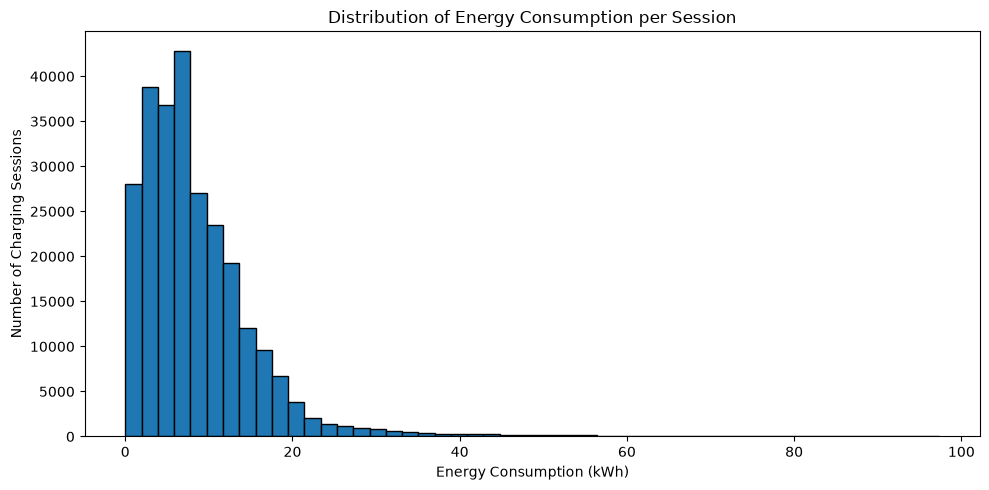

In [ ]:
# Cell 34: Plot energy consumption per session
plt.figure(figsize=(10, 5))

plt.hist(
    df["Energy (kWh)"],
    bins=50,
    edgecolor="black"
)

plt.xlabel("Energy Consumption (kWh)")
plt.ylabel("Number of Charging Sessions")
plt.title("Distribution of Energy Consumption per Session")

plt.tight_layout()
plt.show()


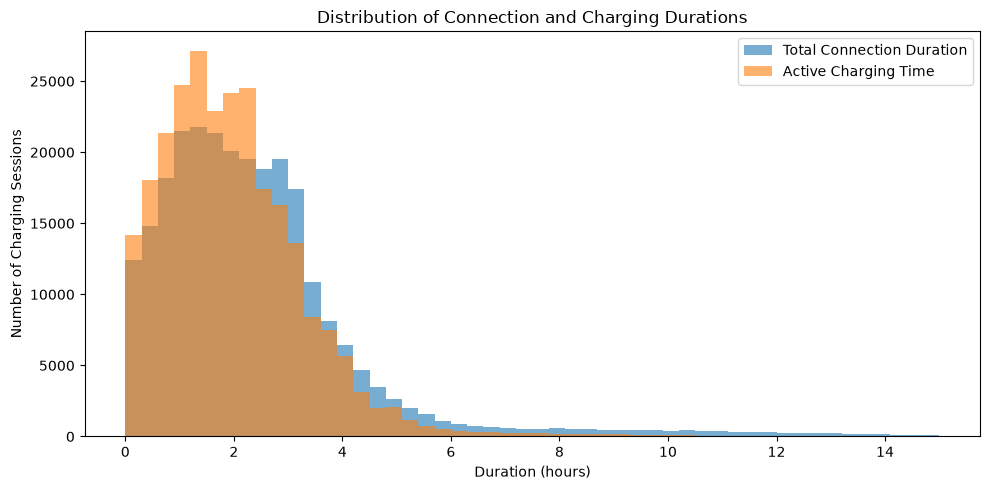

In [ ]:
# Cell 35: Compare connection and charging durations
valid_durations = df[
    (df["Total Duration Hours"] >= df["Charging Time Hours"]) &
    (df["Charging Time Hours"] >= 0)
]

plt.figure(figsize=(10, 5))

plt.hist(
    valid_durations["Total Duration Hours"],
    bins=50,
    alpha=0.6,
    label="Total Connection Duration",
    range=(0, 15)
)

plt.hist(
    valid_durations["Charging Time Hours"],
    bins=50,
    alpha=0.6,
    label="Active Charging Time",
    range=(0, 15)
)

plt.xlabel("Duration (hours)")
plt.ylabel("Number of Charging Sessions")
plt.title("Distribution of Connection and Charging Durations")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
# Cell 36: Summarize idle time
valid_idle = df[
    (df["Idle Time Hours"] >= 0) &
    (~df["Timestamp Error"])
].copy()

# Calculate idle time in minutes
valid_idle["Idle Time Minutes"] = (
    valid_idle["Idle Time Hours"] * 60
)

# Summarize idle time
print("Average idle time (minutes):",
      round(valid_idle["Idle Time Minutes"].mean(), 2))

print("Median idle time (minutes):",
      round(valid_idle["Idle Time Minutes"].median(), 2))

print("Sessions idle for more than 30 minutes:",
      round(
          (valid_idle["Idle Time Minutes"] > 30).mean() * 100,
          2
      ), "%")

print("Sessions idle for more than 60 minutes:",
      round(
          (valid_idle["Idle Time Minutes"] > 60).mean() * 100,
          2
      ), "%")


Average idle time (minutes): 28.93
Median idle time (minutes): 0.43
Sessions idle for more than 30 minutes: 20.38 %
Sessions idle for more than 60 minutes: 12.04 %


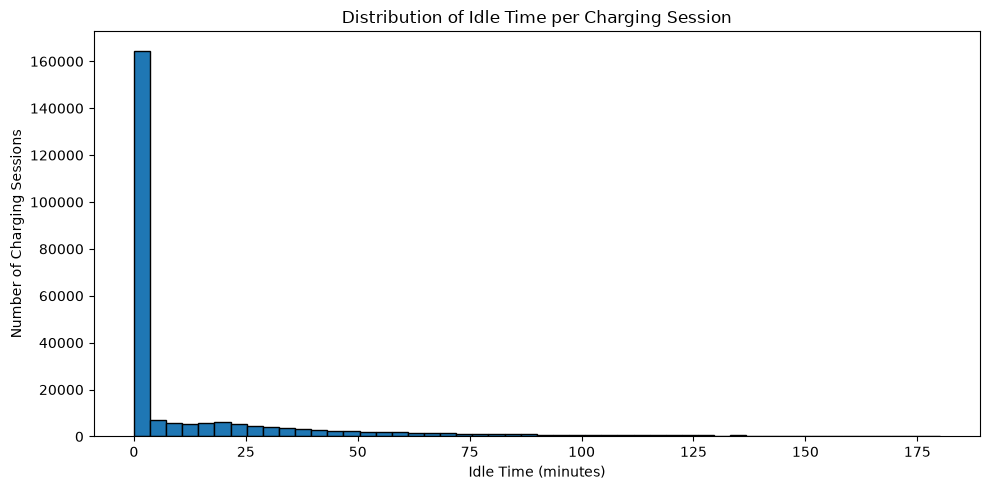

In [ ]:
# Cell 37: Plot idle time distribution
plt.figure(figsize=(10, 5))

plt.hist(
    valid_idle["Idle Time Minutes"],
    bins=50,
    range=(0, 180),
    edgecolor="black"
)

plt.xlabel("Idle Time (minutes)")
plt.ylabel("Number of Charging Sessions")
plt.title("Distribution of Idle Time per Charging Session")

plt.tight_layout()
plt.show()


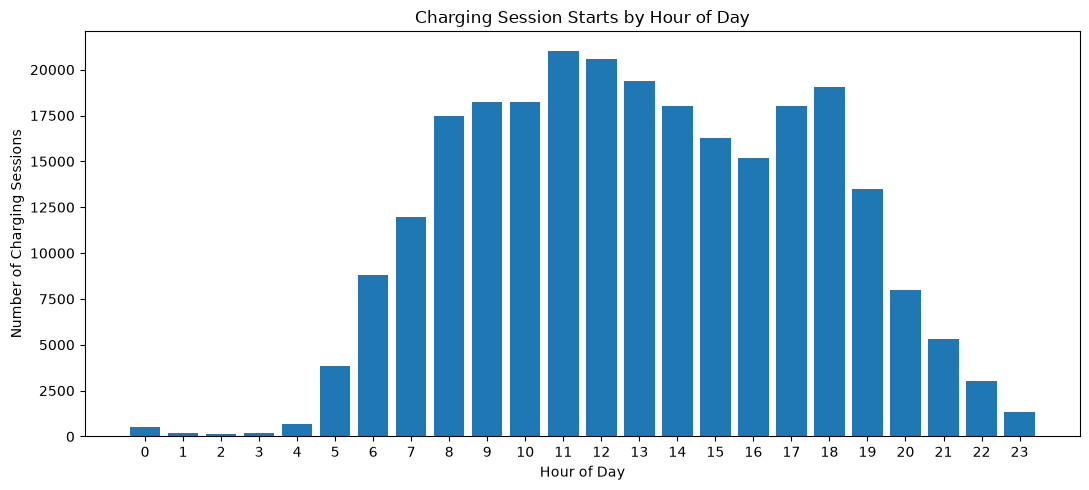

In [ ]:
# Cell 38: Plot charging starts by hour
df["Start Hour"] = df["Start Date"].dt.hour

# Count the number of sessions starting in each hour
hourly_starts = (
    df["Start Hour"]
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)

# Visualize hourly charging starts
plt.figure(figsize=(11, 5))

plt.bar(
    hourly_starts.index,
    hourly_starts.values
)

plt.xlabel("Hour of Day")
plt.ylabel("Number of Charging Sessions")
plt.title("Charging Session Starts by Hour of Day")
plt.xticks(range(24))

plt.tight_layout()
plt.show()


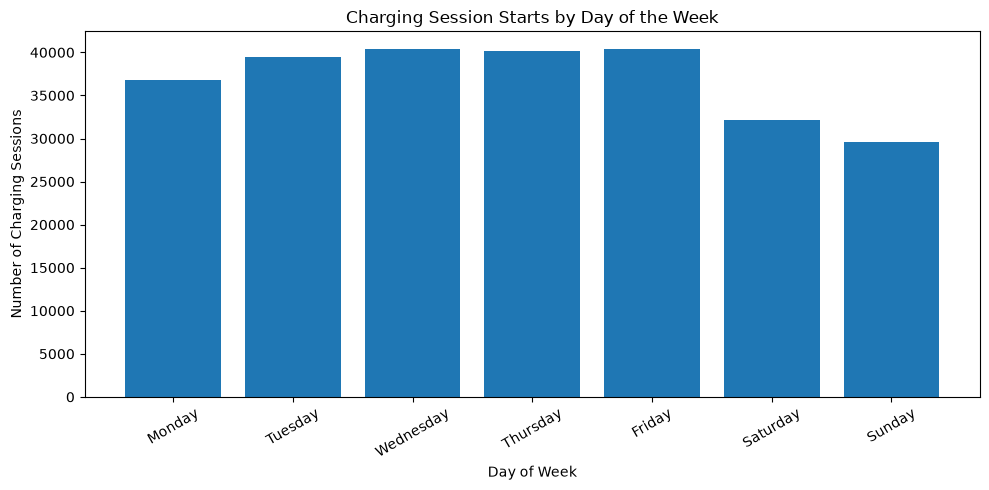

In [ ]:
# Cell 39: Plot charging starts by weekday
# Extract day of week (Monday = 0, Sunday = 6)
df["Day of Week"] = df["Start Date"].dt.dayofweek

day_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Count charging sessions by weekday
weekly_starts = (
    df["Day of Week"]
    .value_counts()
    .reindex(range(7), fill_value=0)
    .sort_index()
)

plt.figure(figsize=(10, 5))

plt.bar(day_names, weekly_starts.values)

plt.xlabel("Day of Week")
plt.ylabel("Number of Charging Sessions")
plt.title("Charging Session Starts by Day of the Week")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


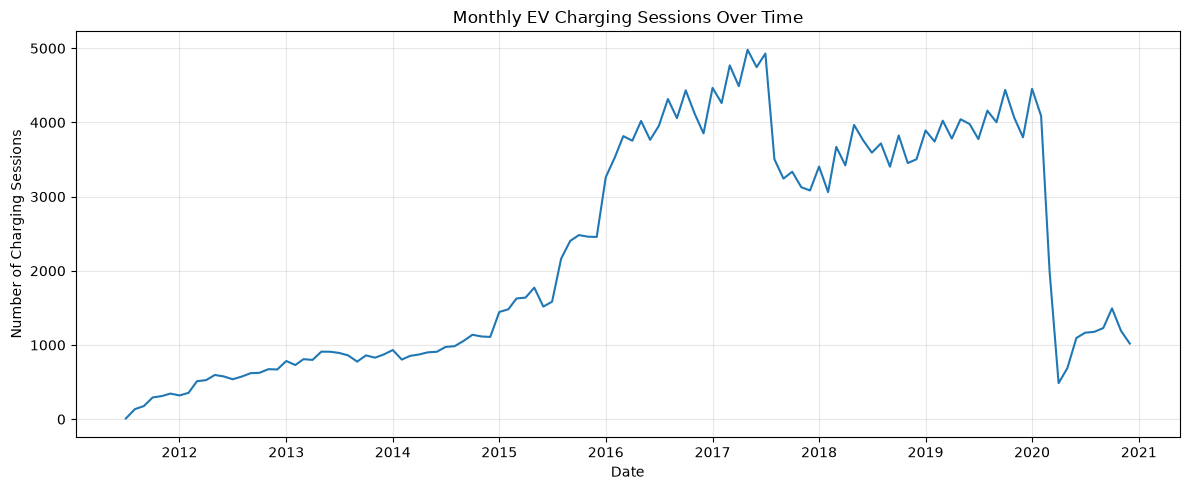

In [ ]:
# Cell 40: Plot monthly charging activity
df["Year"] = df["Start Date"].dt.year
df["Month"] = df["Start Date"].dt.to_period("M")

# Count charging sessions by month
monthly_sessions = (
    df.groupby("Month")
    .size()
)

# Convert PeriodIndex to timestamps for plotting
monthly_sessions.index = monthly_sessions.index.to_timestamp()

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sessions.index,
    monthly_sessions.values
)

plt.xlabel("Date")
plt.ylabel("Number of Charging Sessions")
plt.title("Monthly EV Charging Sessions Over Time")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


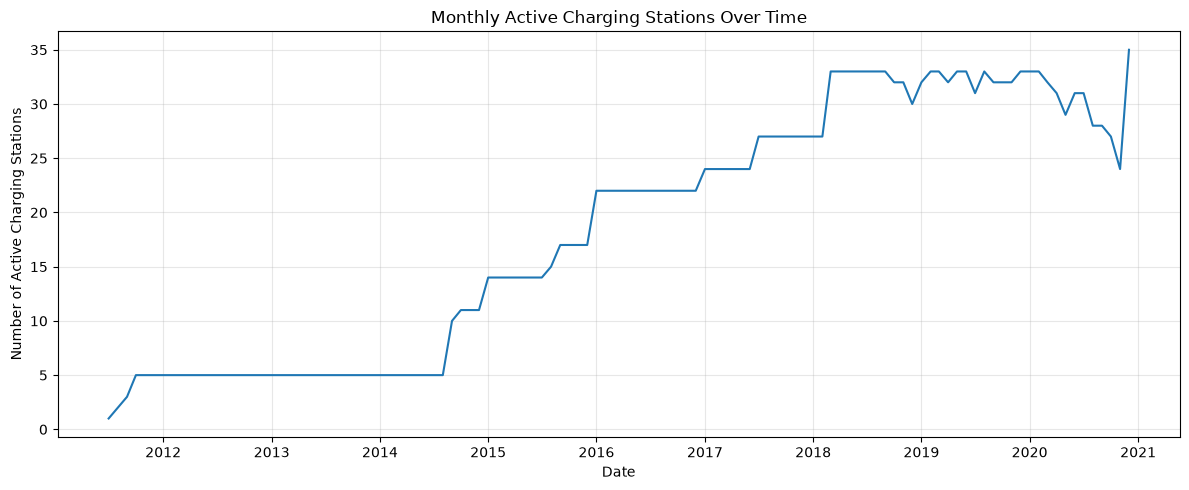

In [ ]:
# Cell 41: Plot active stations per month
monthly_active_stations = (
    df.groupby("Month")["Station Name"]
    .nunique()
)

# Convert PeriodIndex to timestamps
monthly_active_stations.index = (
    monthly_active_stations.index.to_timestamp()
)

# Plot active stations over time
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_active_stations.index,
    monthly_active_stations.values
)

plt.xlabel("Date")
plt.ylabel("Number of Active Charging Stations")
plt.title("Monthly Active Charging Stations Over Time")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


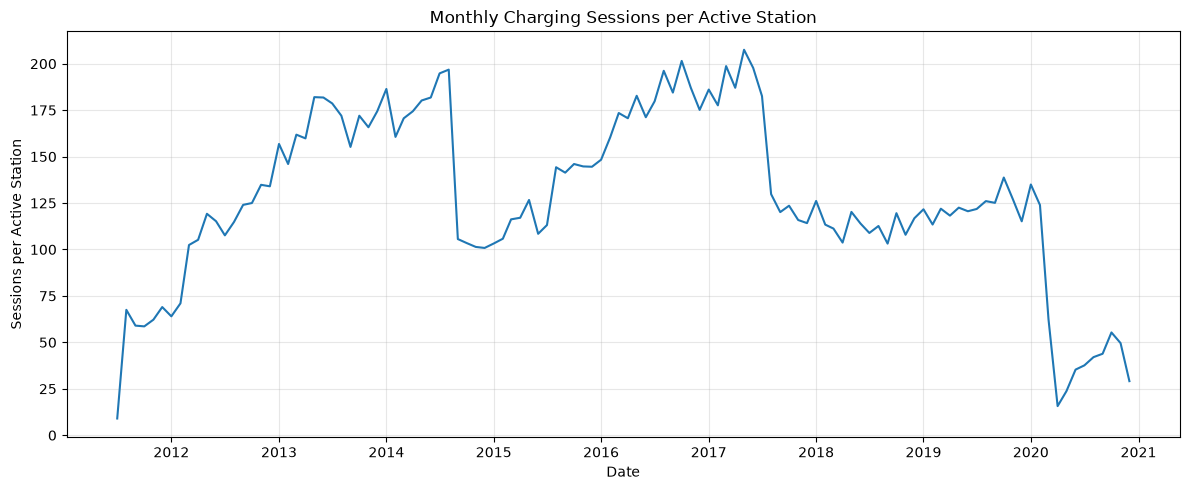

In [ ]:
# Cell 42: Plot monthly sessions per active station
# Calculate average monthly sessions per active station
sessions_per_station = (
    monthly_sessions / monthly_active_stations
)

plt.figure(figsize=(12, 5))

plt.plot(
    sessions_per_station.index,
    sessions_per_station.values
)

plt.xlabel("Date")
plt.ylabel("Sessions per Active Station")
plt.title("Monthly Charging Sessions per Active Station")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Cell 43: Count sessions per station
station_sessions = (
    df["Station Name"]
    .value_counts()
)

print("Number of unique stations:", len(station_sessions))

display(station_sessions.head(15))


Number of unique stations: 47


Station Name
PALO ALTO CA / HAMILTON #2        23681
PALO ALTO CA / HAMILTON #1        14845
PALO ALTO CA / WEBSTER #1         14406
PALO ALTO CA / BRYANT #2          14303
PALO ALTO CA / HIGH #4            13851
PALO ALTO CA / BRYANT #1          13396
PALO ALTO CA / WEBSTER #2         12652
PALO ALTO CA / CAMBRIDGE #1       11154
PALO ALTO CA / HIGH #1            10749
PALO ALTO CA / WEBSTER #3         10472
PALO ALTO CA / TED THOMPSON #1     9809
PALO ALTO CA / CAMBRIDGE #2        9248
PALO ALTO CA / MPL #6              8979
PALO ALTO CA / HIGH #3             8316
PALO ALTO CA / MPL #4              7763
Name: count, dtype: int64

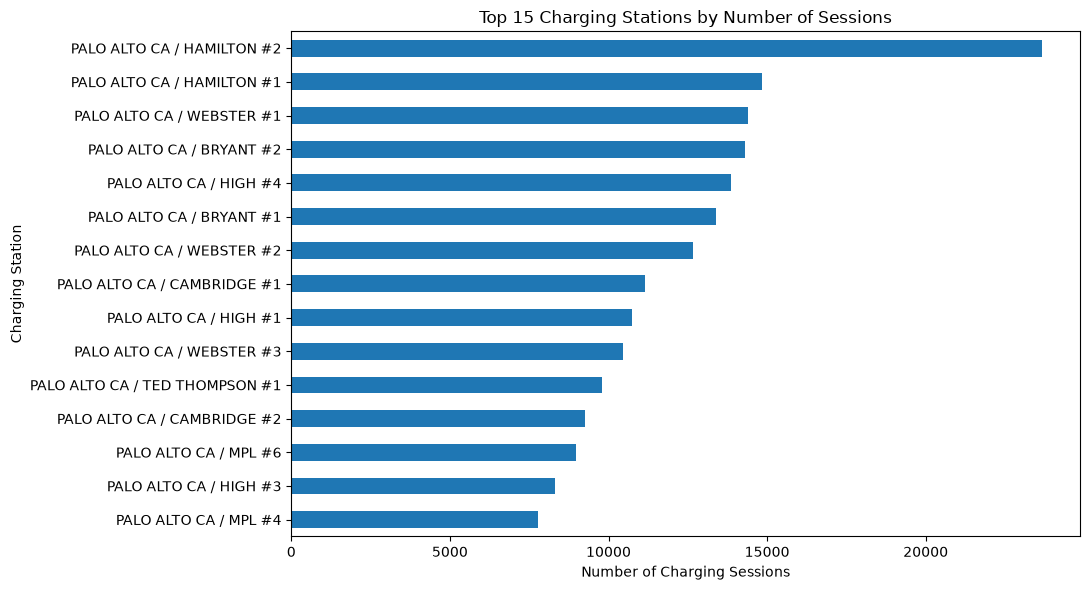

In [ ]:
# Cell 44: Plot top stations by session count
plt.figure(figsize=(11, 6))

station_sessions.head(15).sort_values().plot(
    kind="barh"
)

plt.xlabel("Number of Charging Sessions")
plt.ylabel("Charging Station")
plt.title("Top 15 Charging Stations by Number of Sessions")

plt.tight_layout()
plt.show()


In [ ]:
# Cell 45: Select 2019 sessions
df_2019 = df[df["Start Date"].dt.year == 2019].copy()

# Count sessions per station
station_sessions_2019 = (
    df_2019["Station Name"]
    .value_counts()
)

print("Total sessions in 2019:", len(df_2019))
print("Stations with recorded sessions:", len(station_sessions_2019))

display(station_sessions_2019.head(15))


Total sessions in 2019: 47705
Stations with recorded sessions: 33


Station Name
PALO ALTO CA / HAMILTON #2        3735
PALO ALTO CA / WEBSTER #1         2585
PALO ALTO CA / HIGH #3            2380
PALO ALTO CA / CAMBRIDGE #3       2212
PALO ALTO CA / WEBSTER #2         2174
PALO ALTO CA / CAMBRIDGE #1       2131
PALO ALTO CA / CAMBRIDGE #5       2039
PALO ALTO CA / BRYANT #6          2036
PALO ALTO CA / HIGH #2            1944
PALO ALTO CA / BRYANT #5          1937
PALO ALTO CA / WEBSTER #3         1782
PALO ALTO CA / HIGH #1            1765
PALO ALTO CA / TED THOMPSON #1    1755
PALO ALTO CA / CAMBRIDGE #4       1656
PALO ALTO CA / HIGH #4            1553
Name: count, dtype: int64

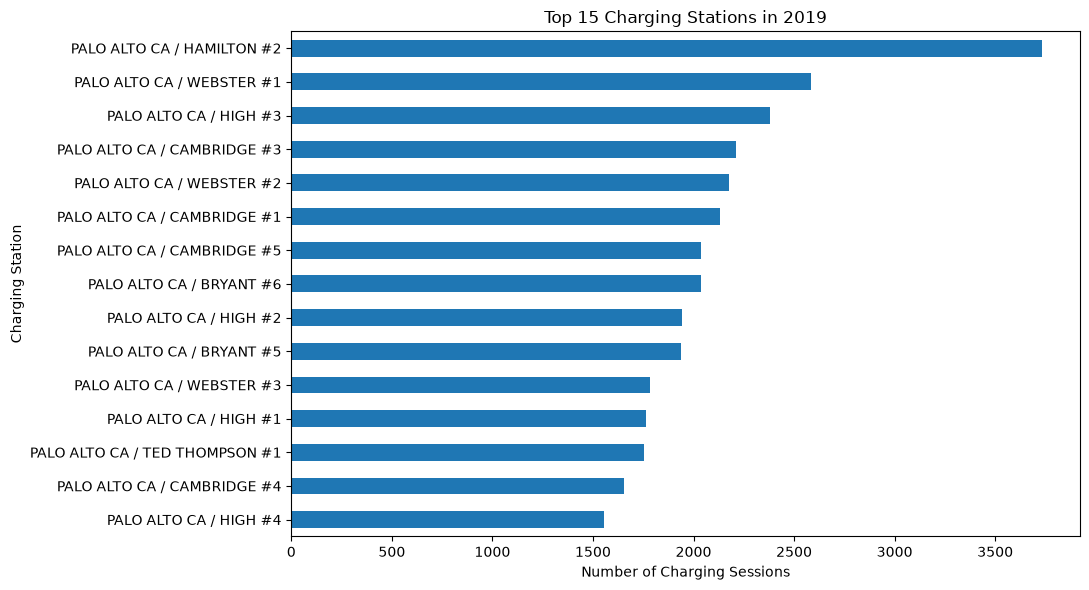

In [ ]:
# Cell 46: Plot top 2019 stations
plt.figure(figsize=(11, 6))

station_sessions_2019.head(15).sort_values().plot(
    kind="barh"
)

plt.xlabel("Number of Charging Sessions")
plt.ylabel("Charging Station")
plt.title("Top 15 Charging Stations in 2019")

plt.tight_layout()
plt.show()


In [ ]:
# Cell 47: Calculate 2019 energy by station
station_energy_2019 = (
    df_2019.groupby("Station Name")["Energy (kWh)"]
    .sum()
    .sort_values(ascending=False)
)

display(station_energy_2019.head(15))


Station Name
PALO ALTO CA / HAMILTON #2        29594.017
PALO ALTO CA / WEBSTER #1         27275.906
PALO ALTO CA / HIGH #3            22346.366
PALO ALTO CA / WEBSTER #2         21888.168
PALO ALTO CA / TED THOMPSON #1    19072.284
PALO ALTO CA / BRYANT #6          18629.960
PALO ALTO CA / WEBSTER #3         18303.103
PALO ALTO CA / HIGH #2            18075.212
PALO ALTO CA / BRYANT #5          17968.884
PALO ALTO CA / CAMBRIDGE #1       16522.678
PALO ALTO CA / HIGH #1            15987.350
PALO ALTO CA / CAMBRIDGE #3       15608.187
PALO ALTO CA / CAMBRIDGE #5       15389.253
PALO ALTO CA / HIGH #4            14760.990
PALO ALTO CA / BRYANT #4          13446.239
Name: Energy (kWh), dtype: float64

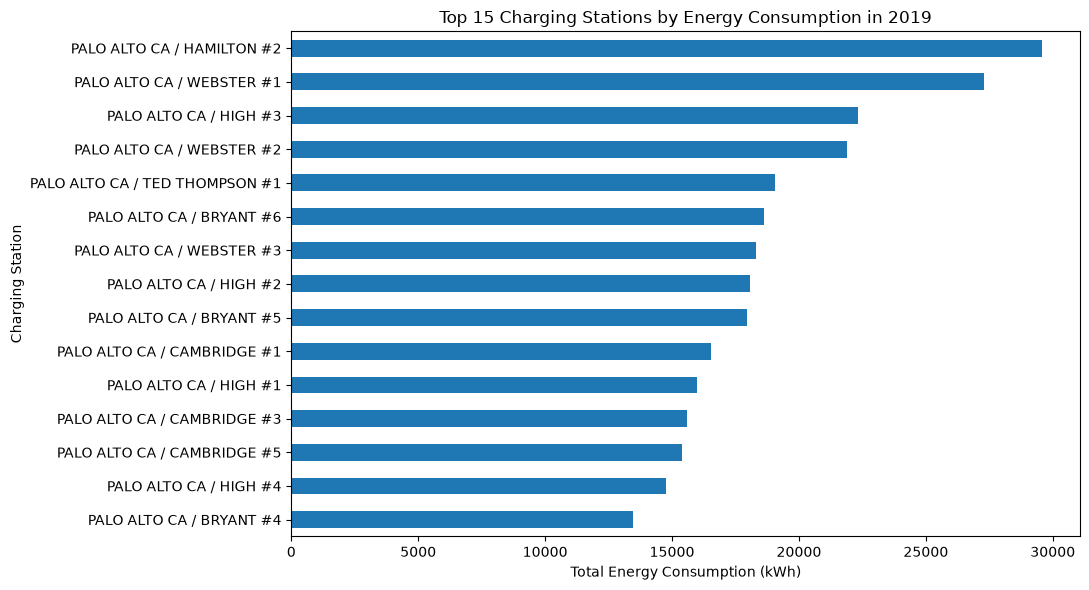

In [ ]:
# Cell 48: Plot 2019 energy by station
plt.figure(figsize=(11, 6))

station_energy_2019.head(15).sort_values().plot(
    kind="barh"
)

plt.xlabel("Total Energy Consumption (kWh)")
plt.ylabel("Charging Station")
plt.title("Top 15 Charging Stations by Energy Consumption in 2019")

plt.tight_layout()
plt.show()


In [ ]:
# Cell 49: Summarize average energy by station
station_avg_energy = (
    df_2019.groupby("Station Name")["Energy (kWh)"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

station_avg_energy.columns = [
    "Number of Sessions",
    "Mean Energy (kWh)",
    "Median Energy (kWh)"
]

display(station_avg_energy.round(2).head(15))


,Number of Sessions,Mean Energy (kWh),Median Energy (kWh)
Station Name,,,
PALO ALTO CA / MPL #1,17,18.85,8.07
PALO ALTO CA / MPL #2,46,13.92,7.03
PALO ALTO CA / RINCONADA LIB 1,810,12.35,7.01
PALO ALTO CA / RINCONADA LIB 2,756,11.93,6.94
PALO ALTO CA / TED THOMPSON #2,1166,11.25,9.62
PALO ALTO CA / TED THOMPSON #1,1755,10.87,8.64
PALO ALTO CA / RINCONADA LIB 3,827,10.78,6.66
PALO ALTO CA / BRYANT #4,1253,10.73,9.25
PALO ALTO CA / WEBSTER #1,2585,10.55,8.28


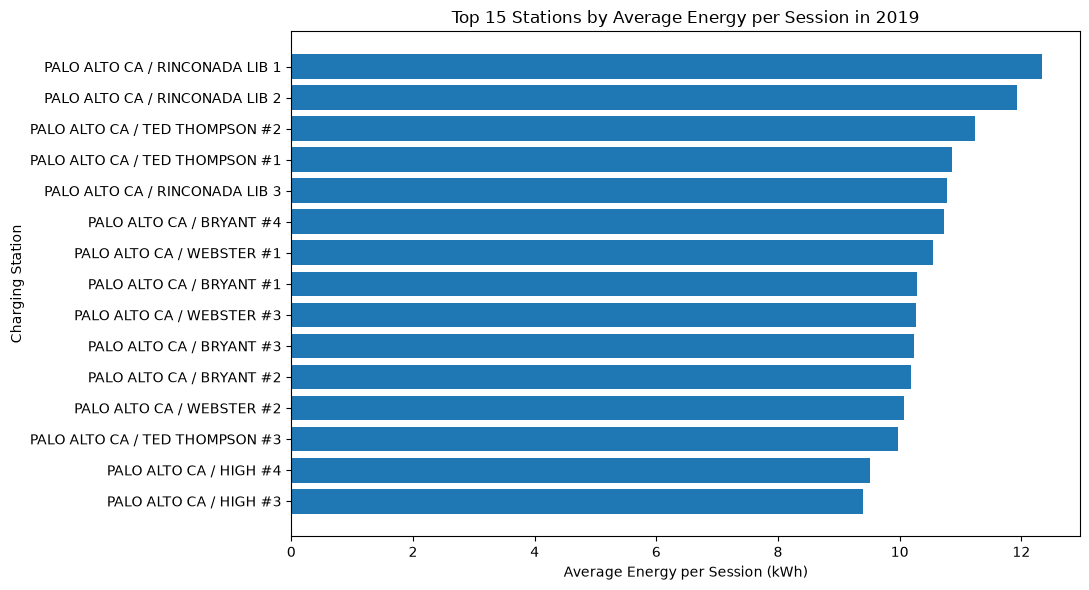

In [ ]:
# Cell 50: Plot average energy for stations with sufficient sessions
station_avg_filtered = station_avg_energy[
    station_avg_energy["Number of Sessions"] >= 100
]

top_avg_energy = (
    station_avg_filtered
    .sort_values("Mean Energy (kWh)", ascending=False)
    .head(15)
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_avg_energy.index[::-1],
    top_avg_energy["Mean Energy (kWh)"][::-1]
)

plt.xlabel("Average Energy per Session (kWh)")
plt.ylabel("Charging Station")
plt.title("Top 15 Stations by Average Energy per Session in 2019")

plt.tight_layout()
plt.show()


In [ ]:
# Cell 51: Summarize charging sessions per user
valid_users = df[
    df["User ID"].notna() &
    (df["User ID"].astype(str).str.strip() != "0")
].copy()

# Count charging sessions per user
sessions_per_user = valid_users["User ID"].value_counts()

print("Number of unique users:", len(sessions_per_user))
print("Average sessions per user:", round(sessions_per_user.mean(), 2))
print("Median sessions per user:", sessions_per_user.median())

print("Users with only 1 session:",
      (sessions_per_user == 1).sum())

print("Users with at least 10 sessions:",
      (sessions_per_user >= 10).sum())

display(sessions_per_user.describe())


Number of unique users: 27684
Average sessions per user: 9.08
Median sessions per user: 2.0
Users with only 1 session: 12912
Users with at least 10 sessions: 4068


count    27684.000000
mean         9.076145
std         32.335570
min          1.000000
25%          1.000000
50%          2.000000
75%          4.000000
max        947.000000
Name: count, dtype: float64

In [ ]:
# Cell 52: Summarize user activity periods
user_activity = valid_users.groupby("User ID").agg(
    First_Session=("Start Date", "min"),
    Last_Session=("Start Date", "max"),
    Number_of_Sessions=("Start Date", "count")
)

# Calculate days between first and last session
user_activity["Observed_Days"] = (
    user_activity["Last_Session"] -
    user_activity["First_Session"]
).dt.days

# Summarize user activity
display(
    user_activity[
        ["Number_of_Sessions", "Observed_Days"]
    ].describe().round(2)
)


,Number_of_Sessions,Observed_Days
count,27684.00,27684.00
mean,9.08,244.98
std,32.34,458.74
min,1.00,0.00
25%,1.00,0.00
50%,2.00,6.00
75%,4.00,283.00
max,947.00,2874.00


In [ ]:
# Cell 53: Monthly idle hours

valid_idle["Year"] = valid_idle["Start Date"].dt.year
valid_idle["Month"] = valid_idle["Start Date"].dt.to_period("M")

monthly_idle = (
    valid_idle.groupby("Month")['Idle Time Hours'].sum()
)

monthly_idle.index = monthly_idle.index.to_timestamp()

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_idle.index,
    monthly_idle.values
)

plt.xlabel("Date")
plt.ylabel("Number of Idle Hours")
plt.title("Monthly Idle Hours Over Time")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()